# Buổi B4: Chế biến nguyên liệu, thang đo, cột chữ và ô trống

**Hiện trường.** Hai việc còn tồn đọng từ các buổi trước:

- **Chị Hạnh** ở B3 gặp bảng hệ số lộn xộn: `s5` có hệ số 67, `bmi` chỉ 5,9, nhưng đó là vì **đơn vị đo khác nhau**. Chị muốn một bảng xếp hạng công bằng.
- **Chị Mai** (vườn hoa iris ở B1) muốn đưa **tên loài** vào mô hình, vì ta đã thấy ba loài làm đường thẳng chung kém ở loài cánh hẹp. Nhưng tên loài là *chữ*, mà máy chỉ ăn số.

Cả hai đều là chuyện **chế biến nguyên liệu trước khi cho máy ăn**. Cộng thêm chuyện cũ: dữ liệu có thể có **ô trống**.

**Câu hỏi của buổi này:** *chuẩn hóa, mã hóa chữ và xử lý ô trống, làm thế nào cho đúng và cho gọn?*

**Mindset của người làm dữ liệu:** mọi bước chế biến đều **học từ dữ liệu** (trung bình bao nhiêu, có những loài nào, số điền khuyết là gì). Vì vậy phải học **chỉ từ tập học**, rồi áp dụng nguyên xi cho tập thi. Công cụ gói gọn quy tắc này tên là **pipeline**.

**Lưu ý:** dữ liệu mẫu để học. Buổi này dùng lại cú pháp từ A1 đến B3 mà không giải thích lại.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Chuẩn hóa thang đo: `fit` và `transform` bằng mắt thấy |
| Chặng 2 | Sau chuẩn hóa: hệ số đọc công bằng, nhưng điểm số thì không đổi |
| Chặng 3 | Pipeline: gói chế biến và mô hình thành một khối |
| Chặng 4 | Cột chữ: mã hóa one-hot và ba đường song song |
| Chặng 5 | Ô trống: điền khuyết đúng chỗ |
| Chặng 6 | Ráp trọn bộ: ColumnTransformer |

## Chặng 1: Chuẩn hóa thang đo, `fit` và `transform` bằng mắt thấy

**Câu hỏi:** các cột đang đo bằng đơn vị rất khác nhau. Làm sao đưa về cùng thước?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
patients = load_diabetes(as_frame=True, scaled=False).frame
X = patients.drop(columns="target")
y = patients["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.agg(["mean", "std"]).round(2))

        age   sex    bmi     bp      s1      s2     s3    s4    s5     s6
mean  48.92  1.47  26.54  94.99  188.74  114.92  49.52  4.08  4.65  91.72
std   12.76  0.50   4.39  14.08   34.73   30.42  12.78  1.30  0.52  11.68


**Giải thích từng dòng**

- `from ... import ... (ba dòng)`: (đã học) bộ đồ nghề quen.
- `X, y, X_train, ... = ...`: (đã học ở B3) X là mọi cột trừ `target`, chia sổ cùng hạt giống 42.
- `X_train.agg(["mean", "std"]).round(2)`: (đã học `agg` ở B1 trong `groupby`) ở đây dùng trực tiếp trên bảng: tính **trung bình và độ lệch chuẩn của từng cột** cùng lúc.

**Cách đọc**

- **Con số:** trung bình của các cột dao động từ **1,5** (`sex`) đến **189** (`s1`); độ lệch chuẩn từ **0,5** (`sex`, `s5`) đến **35** (`s1`).
- **Bức tranh:** như đem so *"mét"* với *"mi-li-mét"*: cột to cột nhỏ lệch nhau cả trăm lần. Để so công bằng, ta đổi mỗi cột thành **"cách trung bình bao nhiêu bước chuẩn"**: *(giá trị − trung bình) / độ lệch chuẩn*. Kết quả gọi là **điểm chuẩn hóa** (z-score): trung bình 0, độ lệch chuẩn 1, đơn vị không còn là điểm hay cm mà là *"bước chuẩn"*.

Sklearn có công cụ làm việc này, và nó đi theo đúng khuôn **`fit` rồi `transform`** mà ta đã nhắc ở B1:

In [3]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
print("learned means:", scaler.mean_.round(1))
print("learned stds :", scaler.scale_.round(2))

learned means: [ 48.9   1.5  26.5  95.  188.7 114.9  49.5   4.1   4.7  91.7]
learned stds : [12.74  0.5   4.38 14.06 34.68 30.38 12.76  1.29  0.52 11.66]


**Giải thích từng dòng**

- `from sklearn.preprocessing import StandardScaler`: module `preprocessing` (tiền xử lý) chứa các công cụ **biến đổi dữ liệu**. `StandardScaler` là công cụ chuẩn hóa z-score.
- `scaler = StandardScaler()`: tạo công cụ, chưa học gì.
- `scaler.fit(X_train)`: **`fit` ở đây nghĩa là "đi đo"**: công cụ nhìn **tập học** và ghi lại **trung bình và độ lệch chuẩn của từng cột**. Nó *không* thay đổi dữ liệu. Chú ý: chỉ nhìn `X_train`, không nhìn `y`, không nhìn `X_test`.
- `scaler.mean_ / scaler.scale_`: những gì công cụ đã ghi lại (dấu gạch dưới cuối quen thuộc: có sau `fit`). `scale_` là độ lệch chuẩn.

In [4]:
Z_train = scaler.transform(X_train)
Z_test = scaler.transform(X_test)
print("type:", type(Z_train).__name__, "| shape:", Z_train.shape)
print("train column means ~0:", Z_train.mean(axis=0).round(2))
print("test  column means   :", Z_test.mean(axis=0).round(2))

type: ndarray | shape: (353, 10)
train column means ~0: [-0. -0. -0. -0. -0.  0. -0. -0. -0.  0.]
test  column means   : [-0.15 -0.02 -0.18 -0.12  0.06  0.08  0.1  -0.04 -0.13 -0.19]


**Giải thích từng dòng**

- `Z_train = scaler.transform(X_train)`: **`transform` là "áp dụng cái đã đo"**: trừ trung bình, chia độ lệch chuẩn **mà `fit` đã ghi**, cho từng cột. Kết quả là một mảng numpy.
- `Z_test = scaler.transform(X_test)`: tập thi cũng đi qua **chính cái thước ấy** (trung bình và độ lệch chuẩn **của tập học**). Không đo lại trên tập thi.
- `Z_train.mean(axis=0)`: `axis=0` nghĩa là "tính **dọc theo cột**" (trung bình của từng cột). `axis=1` là theo dòng.

**Cách đọc**

- **Con số:** `scaler` ghi nhớ trung bình (tuổi 48,9; BMI 26,5...) và độ lệch chuẩn (tuổi 12,7; BMI 4,38...). Trung bình các cột tập học đúng bằng **0**; trung bình tập thi **gần 0 nhưng không đúng 0** (từ −0,19 đến +0,10).
- **Bức tranh:** tập thi không đúng 0 là **bình thường và đúng**: thước đo được may từ tập học, rồi mang đi đo tập thi. Giống như thợ may số đo từ khách cũ, rồi mặc thử cho khách mới; khách mới không vừa khít là chuyện tự nhiên. Nếu ta "đo lại" trên tập thi để ép về 0, ta **gian lận** (đã nhìn trộm đề thi).
- **Hai lưu ý:** (1) `transform` trả về **mảng numpy**, mất tên cột (cuối buổi có cách giữ tên). (2) `fit` và `transform` tách rời là chủ ý: **`fit` một lần trên tập học, `transform` nhiều lần trên mọi dữ liệu.** Có hàm gộp `fit_transform` cho tập học.

Hình dung kết quả:

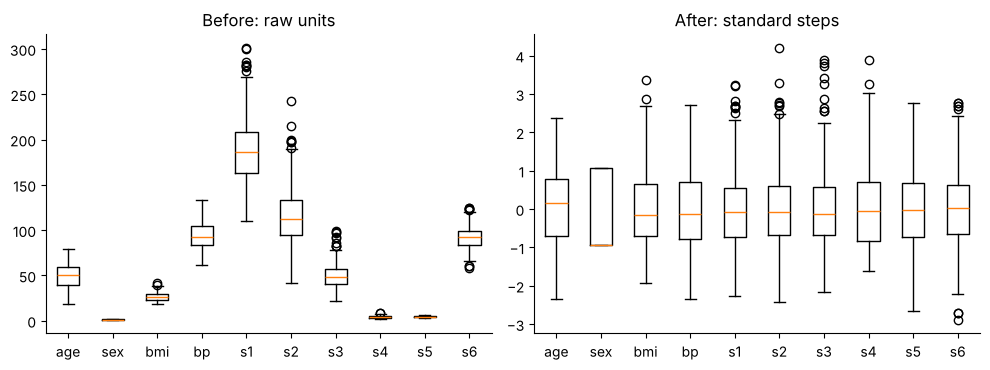

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].boxplot([X_train[c] for c in X_train.columns], tick_labels=X_train.columns)
axes[0].set_title("Before: raw units")
axes[1].boxplot(list(Z_train.T), tick_labels=X_train.columns)
axes[1].set_title("After: standard steps")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `axes[0].boxplot([X_train[c] for c in X_train.columns], tick_labels=X_train.columns)`: (đã học `boxplot`) mười hộp, mỗi cột một hộp, trước chuẩn hóa. List comprehension gom mười cột thành danh sách.
- `axes[1].boxplot(list(Z_train.T), ...)`: `Z_train.T` là **chuyển vị** (đổi dòng thành cột), để mỗi phần tử là một cột; `list(...)` đổi thành danh sách để `boxplot` ăn.

**Cách đọc:** ô trái, các hộp nằm ở **độ cao rất khác nhau** (`s1` ở khoảng 190, `sex` ở khoảng 1,5): chỉ thấy vài cột to, còn lại dẹt sát đáy. Ô phải, **mọi hộp cùng quanh số 0, cùng cỡ**: thông tin về *hình dạng* mỗi cột vẫn còn nguyên, chỉ thang đo là đổi.

**Mang về chặng 1:** chuẩn hóa = (giá trị − trung bình) / độ lệch chuẩn. Dùng `StandardScaler`: **`fit` (đo) trên tập học, `transform` (áp dụng) cho cả tập học và tập thi.** Kết quả là mảng numpy mất tên cột.

## Chặng 2: Sau chuẩn hóa, hệ số đọc công bằng, nhưng điểm số không đổi

**Câu hỏi:** chuẩn hóa xong, mô hình mười cột của B3 thay đổi thế nào?

In [6]:
raw_model = LinearRegression().fit(X_train, y_train)
std_model = LinearRegression().fit(Z_train, y_train)
table = pd.DataFrame({
    "B3 raw coef x std": raw_model.coef_ * X_train.std().to_numpy(),
    "standardized coef": std_model.coef_,
}, index=X.columns).round(1)
print(table.sort_values("standardized coef", key=abs, ascending=False))
print("Test R2: raw", round(raw_model.score(X_test, y_test), 4), "| standardized", round(std_model.score(Z_test, y_test), 4))
print("Standardized intercept:", round(std_model.intercept_, 1), "| mean of y_train:", round(y_train.mean(), 1))

     B3 raw coef x std  standardized coef
s1               -44.5              -44.4
s5                35.2               35.2
bmi               25.6               25.6
s2                24.7               24.6
bp                16.9               16.8
s4                13.2               13.1
sex              -11.5              -11.5
s3                 7.7                7.7
s6                 2.4                2.4
age                1.8                1.8
Test R2: raw 0.4526 | standardized 0.4526
Standardized intercept: 153.7 | mean of y_train: 153.7


**Giải thích từng dòng**

- `raw_model = ...; std_model = ...`: (đã học) hai mô hình: một học từ số thô, một học từ số đã chuẩn hóa. Cùng thuật toán.
- `"B3 raw coef x std": raw_model.coef_ * X_train.std().to_numpy()`: (đã học ở B3) hệ số thô nhân độ lệch chuẩn: cách đọc "công bằng" ta tự làm ở B3.
- `"standardized coef": std_model.coef_`: hệ số của mô hình học trên dữ liệu đã chuẩn hóa.
- `std_model.score(Z_test, y_test)`: chấm trên tập thi **cũng đã được `transform`**: quy tắc của chặng 1.

**Cách đọc**

- **Con số:** hai cột hệ số **gần như trùng nhau** (ví dụ `s1` −44,5 so với −44,4, `s5` 35,2 ở cả hai, `bmi` 25,6 ở cả hai; chênh lệch nhỏ nếu có chỉ do làm tròn và cách tính độ lệch chuẩn). R² thi **y hệt đến 4 chữ số thập phân: 0,4526**. Và `intercept_` bằng **153,7**, chính là **điểm trung bình** của tập học.
- **Bức tranh:** chuẩn hóa **không làm mô hình tốt lên hay xấu đi** (với hồi quy tuyến tính thường), nó chỉ **đổi cách ta đọc**: mỗi hệ số giờ là *"cột này tăng một bước chuẩn thì điểm đổi bao nhiêu"*. `intercept_` giờ có ý nghĩa rõ ràng: **điểm dự đoán của một bệnh nhân hoàn toàn trung bình ở mọi chỉ số**, và đó đúng là điểm trung bình.
- **Vì sao vẫn nên chuẩn hóa nếu điểm số không đổi?** Hai lý do: (1) để **đọc và so hệ số** công bằng; (2) vì nhiều mô hình khác (Ridge và Lasso ở B6, k láng giềng, mạng nơ-ron) **bị ảnh hưởng nặng bởi thang đo**, nên chuẩn hóa là thói quen đúng.
- **Trả lời chị Hạnh:** xếp theo trị tuyệt đối, `s1` (−44), `s5` (35), `bmi` (26), `s2` (25), `bp` (17)... Nhưng đừng quên chặng 5 ở B3: `s1` và `s2` là cặp sinh đôi, hệ số hai cột này **chưa đáng tin**. Bảng xếp hạng chỉ đáng tin với các cột ít tương quan nhau.

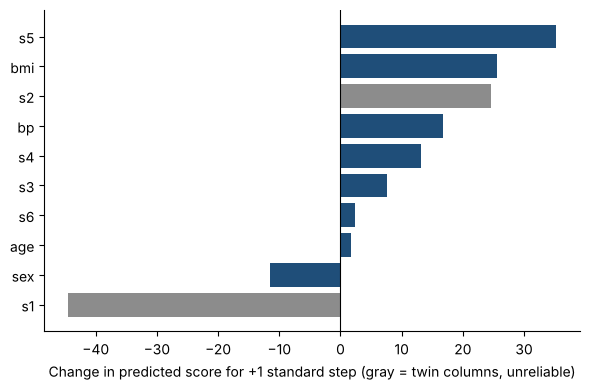

In [7]:
chart = pd.Series(std_model.coef_, index=X.columns).sort_values()
plt.barh(chart.index, chart.values, color=np.where(chart.index.isin(["s1", "s2"]), GRAY, BLUE))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Change in predicted score for +1 standard step (gray = twin columns, unreliable)")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `chart = pd.Series(std_model.coef_, index=X.columns).sort_values()`: (đã học) hệ số chuẩn hóa kèm tên cột, xếp tăng dần.
- `color=np.where(chart.index.isin(["s1", "s2"]), GRAY, BLUE)`: `.isin([...])` hỏi "tên cột này có nằm trong danh sách không" (ra Đúng/Sai); `np.where` tô **xám** hai cột sinh đôi và **xanh** các cột còn lại để người xem biết chỗ nào đáng nghi.

**Mang về chặng 2:** với hồi quy tuyến tính, chuẩn hóa **không đổi điểm số** nhưng làm hệ số **so sánh được** và `intercept_` có nghĩa (điểm của người trung bình). Cột nào tương quan mạnh với cột khác thì vẫn phải nghi ngờ hệ số, dù đã chuẩn hóa.

## Chặng 3: Pipeline, gói chế biến và mô hình thành một khối

**Câu hỏi:** mỗi lần phải nhớ "fit scaler trên train, transform cả train và test, rồi fit model..." thì dễ nhầm. Có cách nào gói lại?

Có: **pipeline** (đường ống). Nó xếp các bước thành một dây chuyền: dữ liệu vào đầu, qua từng bước chế biến, đến mô hình cuối cùng.

In [8]:
from sklearn.pipeline import make_pipeline
pipe = make_pipeline(StandardScaler(), LinearRegression())
pipe.fit(X_train, y_train)
print("Test R2 through the pipeline:", round(pipe.score(X_test, y_test), 4))
print("Steps:", [name for name, _ in pipe.steps])
print("Scaler learned mean of bmi:", round(pipe[0].mean_[2], 2), "| model coef of bmi:", round(pipe[-1].coef_[2], 1))

Test R2 through the pipeline: 0.4526
Steps: ['standardscaler', 'linearregression']
Scaler learned mean of bmi: 26.54 | model coef of bmi: 25.6


**Giải thích từng dòng**

- `from sklearn.pipeline import make_pipeline`: lấy công cụ ráp pipeline.
- `pipe = make_pipeline(StandardScaler(), LinearRegression())`: xếp **hai bước** theo thứ tự: bước 1 chuẩn hóa, bước 2 mô hình. Mọi bước **trừ bước cuối** phải là bước biến đổi (có `transform`); bước cuối là mô hình (có `predict`).
- `pipe.fit(X_train, y_train)`: **một lệnh `fit` làm hết**: pipeline tự `fit` scaler trên `X_train`, `transform` `X_train`, rồi `fit` mô hình trên kết quả. Tập thi chưa hề được chạm tới.
- `pipe.score(X_test, y_test)`: chấm tập thi: pipeline tự `transform` `X_test` bằng scaler đã `fit` (từ tập học), rồi đưa vào mô hình. **Không thể quên** và **không thể nhầm**.
- `pipe.steps / pipe[0] / pipe[-1]`: `pipe.steps` là danh sách các bước kèm tên tự đặt. `pipe[0]` là bước đầu (scaler), `pipe[-1]` là bước cuối (mô hình): cách chui vào bên trong để đọc `mean_`, `coef_`.

**Cách đọc**

- **Con số:** R² thi qua pipeline là **0,4526**, **y hệt** hai cách làm tay ở chặng 2. Hai bước tên là `standardscaler` và `linearregression` (tự đặt từ tên lớp, viết thường).
- **Bức tranh:** pipeline là **chiếc hộp có một cửa vào, một cửa ra**: nhét bảng thô vào, nhận dự đoán ra. Mọi bước chế biến đã nằm bên trong; bạn không còn phải nhớ thứ tự hay sợ lỡ "fit" nhầm trên tập thi.
- **Vì sao đáng dùng:** pipeline **chống rò rỉ dữ liệu** (bài học A4) theo cấu tạo. Đặc biệt khi ta lặp nhiều lần chia sổ hay kiểm định chéo (phần D), pipeline tự `fit` lại mọi bước **trong từng lần**, đúng như yêu cầu.

Một điều thành thật: với hồi quy tuyến tính, nếu cố tình `fit` scaler trên **cả** tập học lẫn thi (phạm lỗi rò rỉ), R² thi **vẫn như cũ** (đúng 0,4526). Hồi quy tuyến tính **bất biến thang đo** nên che mất lỗi. Với mô hình nhạy thang đo (Ridge, k láng giềng), cùng lỗi đó làm điểm thi **đẹp giả**. Lỗi vô hình thì càng phải có *thói quen* phòng ngừa thay vì trông chờ bị bắt.

**Mang về chặng 3:** `make_pipeline(bước_1, ..., mô_hình)` gói chế biến và mô hình thành **một khối**. `fit`, `predict`, `score` gọi trên khối. Pipeline làm đúng quy tắc "học chỉ từ tập học" tự động.

## Chặng 4: Cột chữ, mã hóa one-hot và ba đường song song

**Câu hỏi:** làm sao đưa **tên loài** vào mô hình của chị Mai?

In [9]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True).frame
flowers = iris.rename(columns={"petal length (cm)": "petal_length", "petal width (cm)": "petal_width"})
flowers["species"] = flowers["target"].map({0: "setosa", 1: "versicolor", 2: "virginica"})
Xf, yf = flowers[["petal_length", "species"]], flowers["petal_width"]
Xf_train, Xf_test, yf_train, yf_test = train_test_split(Xf, yf, test_size=0.2, random_state=42)
try:
    LinearRegression().fit(Xf_train, yf_train)
except ValueError as err:
    print("ValueError:", str(err)[:110])

ValueError: could not convert string to float: 'setosa'


**Giải thích từng dòng**

- `iris = ...; flowers = iris.rename(...)`: (đã học ở B1) dữ liệu hoa iris, đổi tên cột cho dễ gõ.
- `flowers["species"] = flowers["target"].map({...})`: (đã học `.map` ở A6) thêm cột **chữ** tên loài từ mã 0/1/2.
- `Xf, yf = flowers[["petal_length", "species"]], flowers["petal_width"]`: X có **hai cột**: một cột số, một cột chữ. Đáp án vẫn là chiều rộng. Hậu tố `f` (flowers) để khỏi đè lên biến bệnh nhân.
- `LinearRegression().fit(Xf_train, yf_train)`: thử đưa thẳng cột chữ vào.

**Cách đọc:** máy báo lỗi: nó không đổi được chữ `"setosa"` thành số. Ta *không thể* đơn giản đổi `setosa=0, versicolor=1, virginica=2`, vì như vậy ta **dạy máy rằng virginica "gấp đôi" versicolor**, một thứ thứ tự giả không hề có. Cách đúng là **one-hot** (mã hóa một-nóng): mỗi loài thành **một cột 0/1** riêng, cột nào đúng loài thì bằng 1.

In [10]:
pd.get_dummies(Xf_train["species"]).astype(int).head(4).join(Xf_train["species"])

,setosa,versicolor,virginica,species
22,1,0,0,setosa
15,1,0,0,setosa
65,0,1,0,versicolor
11,1,0,0,setosa


**Giải thích từng dòng**

- `pd.get_dummies(Xf_train["species"])`: `get_dummies` chuyển một cột chữ thành **các cột 0/1**, mỗi giá trị khác nhau một cột. Ở đây ra ba cột `setosa`, `versicolor`, `virginica`.
- `.astype(int)`: (đã học) đổi Đúng/Sai thành 0/1 cho dễ đọc.
- `.head(4).join(Xf_train["species"])`: `.head(4)` lấy 4 dòng đầu; `.join(...)` **ghép thêm cột** tên loài gốc bên cạnh để đối chiếu.

**Cách đọc:** mỗi dòng là một bông hoa; **đúng một ô bằng 1**, hai ô còn lại bằng 0: như một bảng trắc nghiệm chọn một đáp án. Giờ máy ăn được. Nhưng `get_dummies` phải làm lại bằng tay cho dữ liệu mới, dễ lệch cột. Công cụ đúng cho pipeline là **`OneHotEncoder`**, cũng theo khuôn `fit` rồi `transform`:

In [11]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
prep = ColumnTransformer([("species", OneHotEncoder(drop="first"), ["species"])], remainder="passthrough")
flower_model = make_pipeline(prep, LinearRegression()).fit(Xf_train, yf_train)
names = prep.get_feature_names_out()
print(pd.Series(flower_model[-1].coef_, index=names).round(3))
print("intercept:", round(flower_model[-1].intercept_, 3))

species__species_versicolor    0.371
species__species_virginica     0.726
remainder__petal_length        0.253
dtype: float64
intercept: -0.122


**Giải thích từng dòng**

- `from sklearn.compose import ColumnTransformer`: công cụ **"cột nào chế biến theo cách nào"**: vì cột số và cột chữ cần xử lý **khác nhau**.
- `ColumnTransformer([("species", OneHotEncoder(drop="first"), ["species"])], remainder="passthrough")`: danh sách các **bộ ba** `(tên_tự_đặt, công_cụ, danh_sách_cột)`. Ở đây: cột `species` đi qua `OneHotEncoder`. `remainder="passthrough"` nghĩa là **các cột còn lại (cột số) cho đi qua nguyên xi**. `drop="first"` bỏ **một** cột one-hot (giải thích bên dưới).
- `flower_model = make_pipeline(prep, LinearRegression()).fit(...)`: ráp thành pipeline và học. `prep` là bước chế biến, mô hình là bước cuối.
- `names = prep.get_feature_names_out()`: danh sách **tên các cột sau chế biến**, để gắn nhãn cho hệ số.

**Cách đọc**

- **Con số:** `intercept_` = **−0,122**; hệ số `species_versicolor` = **+0,371**; hệ số `species_virginica` = **+0,726**; hệ số `petal_length` = **0,253**.
- **Vì sao `drop="first"`:** nếu giữ cả ba cột one-hot thì cột nào cũng suy ra được từ hai cột kia (cộng ba cột luôn bằng 1): thành **cặp sinh đôi hoàn hảo** như `s1`/`s2` ở B3, hệ số bấp bênh. Bỏ một cột thì loài bị bỏ (**setosa**) thành **loài nền (baseline)**, mọi loài khác được đọc **so với loài nền**.
- **Cách đọc hệ số loài:** *"cùng chiều dài cánh hoa, một bông versicolor rộng hơn bông setosa khoảng 0,37 cm; một bông virginica rộng hơn setosa khoảng 0,73 cm."* Và `petal_length` = 0,253 là **độ dốc chung của cả ba loài**: dài thêm 1 cm thì rộng thêm 0,25 cm.
- **Intercept** giờ là điểm xuất phát của **loài nền** (setosa): −0,122. Mỗi loài khác dời điểm xuất phát lên một đoạn.

Hình ảnh nói rõ hơn con số:

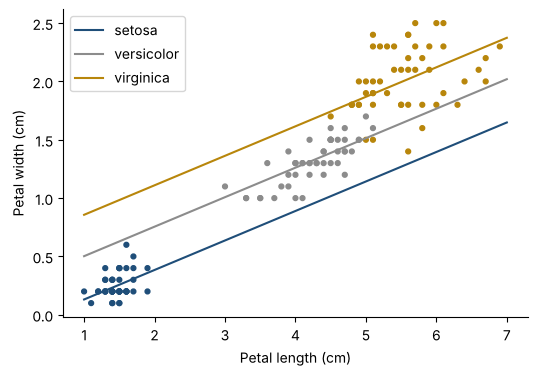

In [12]:
line_x = np.linspace(1, 7, 50)
plt.scatter(flowers["petal_length"], flowers["petal_width"], c=flowers["target"].map({0: BLUE, 1: GRAY, 2: "#B8860B"}), s=12)
for sp, color in [("setosa", BLUE), ("versicolor", GRAY), ("virginica", "#B8860B")]:
    grid = pd.DataFrame({"petal_length": line_x, "species": sp})
    plt.plot(line_x, flower_model.predict(grid), color=color, label=sp)
plt.xlabel("Petal length (cm)"); plt.ylabel("Petal width (cm)")
plt.legend(); plt.show()

**Giải thích từng dòng**

- `grid = pd.DataFrame({"petal_length": line_x, "species": sp})`: bảng 50 dòng: chiều dài chạy từ 1 đến 7, và **cùng một loài** `sp` cho cả 50 dòng (pandas tự lặp giá trị đơn lẻ cho đủ 50 dòng).
- `flower_model.predict(grid)`: pipeline tự one-hot cột `species` rồi mới dự đoán: ta chỉ cần đưa bảng **y như lúc học** (cột chữ nguyên dạng).

**Cách đọc**

- **Con số:** đây là mô hình có **ba đường, cùng độ dốc 0,253, khác điểm xuất phát**.
- **Bức tranh:** ba đường **song song**, mỗi đường nằm trong đám chấm của loài mình. Đường chung ở B1 là *một tấm thước cho cả ba loài*; bây giờ mỗi loài có thước riêng, chỉ khác nhau ở độ cao. Đó chính là ý nghĩa của one-hot trong mô hình tuyến tính: **dời đường lên xuống theo nhóm**.
- **Một giới hạn:** ba đường *song song*, nghĩa là ta giả định cánh hoa dài thêm 1 cm thì rộng thêm cùng một lượng ở mọi loài. Có thể sai (nếu độ dốc mỗi loài khác nhau). Muốn độ dốc riêng thì cần cột "tích" (tương tác), ngoài phạm vi buổi này.

Kết quả có đáng công không?

In [13]:
from sklearn.metrics import mean_absolute_error
base = LinearRegression().fit(Xf_train[["petal_length"]], yf_train)
def error_by_species(pred):
    report = pd.DataFrame({"species": Xf_test["species"], "abs_error": (yf_test - pred).abs(), "width": yf_test})
    g = report.groupby("species").agg(error=("abs_error", "mean"), width=("width", "mean"))
    return (g["error"] / g["width"] * 100).round(0)
compare = pd.DataFrame({
    "B1 line: error %": error_by_species(base.predict(Xf_test[["petal_length"]])),
    "with species: error %": error_by_species(flower_model.predict(Xf_test)),
})
print("MAE  B1 line:", round(mean_absolute_error(yf_test, base.predict(Xf_test[["petal_length"]])), 3), "| with species:", round(mean_absolute_error(yf_test, flower_model.predict(Xf_test)), 3))
print("R2   B1 line:", round(base.score(Xf_test[["petal_length"]], yf_test), 3), "| with species:", round(flower_model.score(Xf_test, yf_test), 3))
compare

MAE  B1 line: 0.168 | with species: 0.133
R2   B1 line: 0.928 | with species: 0.958


,B1 line: error %,with species: error %
species,,
setosa,36.0,34.0
versicolor,10.0,9.0
virginica,13.0,9.0


**Giải thích từng dòng**

- `base = LinearRegression().fit(Xf_train[["petal_length"]], yf_train)`: đường chung kiểu B1 làm mốc so sánh.
- `def error_by_species(pred): ...`: (đã học `def`, `groupby`, `agg`) gói **cách xẻ sai số theo loài** của B1 thành một hàm để dùng lại cho hai mô hình. Hàm trả về sai số **tương đối** theo phần trăm.
- `compare = pd.DataFrame({"...": error_by_species(...), "...": error_by_species(...)})`: ghép hai kết quả cạnh nhau.

**Cách đọc**

- **Con số:** MAE giảm từ **0,168 xuống 0,133 cm**; R² thi tăng từ **0,928 lên 0,958**. Sai số tương đối của virginica giảm từ khoảng **13% xuống 9%**, của versicolor từ khoảng **10% xuống 9%**, nhưng của **setosa chỉ từ khoảng 36% xuống 34%**.
- **Bức tranh:** thêm cột loài **giúp rõ** ở hai loài lớn, **gần như không cứu được** loài cánh hẹp setosa: chiều rộng setosa chỉ khoảng 0,25 cm (và gần như không đổi theo chiều dài), nên sai lệch vài mm vẫn là một phần ba. Vấn đề của setosa không nằm ở *thiếu cột loài* mà ở *chính độ chính xác của phép đo* (thước kẹp, làm tròn 0,1 cm).
- **Bài học nghề:** thêm cột đúng chỗ giúp **nơi nó có thể giúp**. Đừng hứa hẹn quá. Phải nhìn sai số **theo nhóm** (bài học B1) để biết chỗ nào đã được cứu, chỗ nào chưa.

**Mang về chặng 4:** cột chữ phải đổi thành số bằng **one-hot** (mỗi giá trị một cột 0/1); đừng đánh số 0,1,2 vì tạo thứ tự giả. Dùng `drop="first"` để tránh cặp sinh đôi hoàn hảo; hệ số mỗi loài đọc **so với loài nền**. Trong mô hình tuyến tính, one-hot dời đường lên xuống theo nhóm.

## Chặng 5: Ô trống, điền khuyết đúng chỗ

**Câu hỏi:** ở B1 ta thấy `LinearRegression` từ chối ô trống (NaN). Ở A2 ta đã học xóa dòng hoặc điền trung vị. Làm thế nào để điền khuyết **đúng quy tắc** trong pipeline?

Quy tắc giống hệt chuẩn hóa: **giá trị điền (ví dụ trung vị) phải học từ tập học**, rồi dùng nguyên xi cho tập thi. Ta làm "bẩn" dữ liệu bệnh nhân: **xóa ngẫu nhiên 10%** ô ở cột `bmi` và `bp`, ở cả hai tập.

In [14]:
rng = np.random.default_rng(1)
def dirty(df):
    df = df.copy()
    for col in ["bmi", "bp"]:
        df.loc[rng.random(len(df)) < 0.10, col] = np.nan
    return df
Xd_train, Xd_test = dirty(X_train), dirty(X_test)
print("Missing per column (train):", Xd_train.isna().sum()[["bmi", "bp"]].to_dict(), "| rows with any NaN:", int(Xd_train.isna().any(axis=1).sum()), "of", len(Xd_train))

Missing per column (train): {'bmi': 39, 'bp': 26} | rows with any NaN: 64 of 353


**Giải thích từng dòng**

- `def dirty(df):`: hàm làm bẩn một bảng.
- `df = df.copy()`: (đã học) làm việc trên bản sao.
- `df.loc[rng.random(len(df)) < 0.10, col] = np.nan`: `rng.random(n)` sinh `n` số ngẫu nhiên từ 0 đến 1; so với 0,10 ra Đúng/Sai, khoảng **10% Đúng**; `.loc[Đúng/Sai, cột] = np.nan` (đã học ở A2) xóa các ô đó.
- `Xd_train.isna().any(axis=1).sum()`: (đã học `isna`) **mới:** `.any(axis=1)` hỏi "dòng này có **ít nhất một** ô trống không"; cộng lại là số dòng bị trống.

**Cách đọc:** khoảng 10% ô của hai cột bị xóa (39 ô ở `bmi`, 26 ô ở `bp`), nhưng vì xóa ở **hai cột** độc lập, số **dòng có ít nhất một ô trống** là **64 trên 353, khoảng 18%**. Chú ý điều này: xóa cả dòng (`dropna`) sẽ mất gần **một phần năm** dữ liệu. Ba cách xử lý, đặt cạnh nhau:

In [15]:
from sklearn.impute import SimpleImputer
keep = ~Xd_train.isna().any(axis=1)
drop_rows = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()).fit(Xd_train[keep], y_train[keep])
median_all = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()).fit(Xd_train, y_train)
mean_all = make_pipeline(SimpleImputer(strategy="mean"), StandardScaler(), LinearRegression()).fit(Xd_train, y_train)
results = pd.Series({
    "clean data (reference)": pipe.score(X_test, y_test),
    "drop dirty rows in train": drop_rows.score(Xd_test, y_test),
    "fill with median": median_all.score(Xd_test, y_test),
    "fill with mean": mean_all.score(Xd_test, y_test),
}).round(3)
results

clean data (reference)      0.453
drop dirty rows in train    0.449
fill with median            0.449
fill with mean              0.453
dtype: float64

**Giải thích từng dòng**

- `from sklearn.impute import SimpleImputer`: module `impute` (điền khuyết). `SimpleImputer` điền ô trống bằng một **thống kê của cả cột**.
- `keep = ~Xd_train.isna().any(axis=1)`: (đã học `~`) Đúng cho dòng **không** có ô trống nào.
- `SimpleImputer(strategy="median")`: điền bằng **trung vị** của cột (`strategy="mean"` là trung bình). **`fit` ghi nhớ trung vị của tập học; `transform` điền giá trị đó** (cả vào tập thi). Chú ý: bước điền khuyết đứng **trước** bước chuẩn hóa trong pipeline, vì chuẩn hóa cần số.
- `drop_rows = ...fit(Xd_train[keep], y_train[keep])`: cách 1: **bỏ dòng trống khi học**. Tập thi thì **không bỏ được** (không thể từ chối bệnh nhân vì thiếu số), nên pipeline vẫn có bước điền khuyết để xử lý tập thi.
- `median_all / mean_all`: cách 2 và 3: giữ mọi dòng, điền bằng trung vị hoặc trung bình.
- `pd.Series({...}).round(3)`: R² thi của bốn trường hợp.

**Cách đọc**

- **Con số:** dữ liệu sạch cho R² thi **0,453**; sau khi làm bẩn 10% hai cột, bỏ dòng bẩn khi học cho **0,449**, điền trung vị **0,449**, điền trung bình **0,453**. Cả ba cách mất **rất ít** (không quá 0,004).
- **Bức tranh:** ở mức thiếu 10% và với hai cột này, **dù xử lý cách nào kết quả gần như không đổi**: các chỉ số còn lại (đặc biệt `s5`, và các cột tương quan với `bmi`) đã gánh thay phần thông tin bị mất. Sự khác biệt 0,004 nằm trong vùng "may rủi một lần chia" (A4), không nên đọc ra "mean tốt hơn median". Trong tình huống này `SimpleImputer` trong pipeline có lợi thế **thực dụng**: **giữ nguyên mọi dòng** và **áp được cho tập thi**, nơi ta không có quyền "bỏ dòng".
- **Bài học nghề:** (1) Cách điền khuyết rất ít khi quyết định kết quả; **lượng dữ liệu bị thiếu và vì sao thiếu** mới là điều quan trọng. (2) Hỏi *tại sao ô trống*: nếu ô trống mang ý nghĩa (ví dụ "không xét nghiệm vì bệnh nhân khỏe"), điền trung vị sẽ **xóa mất tín hiệu đó**. (3) Luôn học giá trị điền từ tập học.

**Mang về chặng 5:** điền khuyết bằng `SimpleImputer` đặt **trong pipeline**, học trung vị hoặc trung bình **từ tập học**, áp cho tập thi. Cách điền ít khi quyết định kết quả; hãy hỏi vì sao ô bị trống.

## Chặng 6: Ráp trọn bộ, ColumnTransformer

**Câu hỏi:** dữ liệu thật vừa có cột số (cần điền khuyết và chuẩn hóa) vừa có cột chữ (cần one-hot). Gói cả vào một khối được không?

Ta thử với dữ liệu bệnh nhân: cột `sex` là mã 1 hoặc 2 nhưng thực chất là **nhóm**, nên xử lý như cột chữ (one-hot); chín cột kia là số.

In [16]:
numeric_cols = [c for c in X.columns if c != "sex"]
prep_all = ColumnTransformer([
    ("numbers", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric_cols),
    ("group", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(drop="first")), ["sex"]),
])
final = make_pipeline(prep_all, LinearRegression()).fit(Xd_train, y_train)
print("Test R2 on the dirty data, full pipeline:", round(final.score(Xd_test, y_test), 3))
print(pd.Series(final[-1].coef_, index=prep_all.get_feature_names_out()).round(1).sort_values(key=abs, ascending=False).head(6))

Test R2 on the dirty data, full pipeline: 0.449
numbers__s1      -45.8
numbers__s5       36.4
numbers__s2       26.6
numbers__bmi      23.8
group__sex_2.0   -23.5
numbers__bp       16.8
dtype: float64


**Giải thích từng dòng**

- `numeric_cols = [c for c in X.columns if c != "sex"]`: (đã học) chín cột số.
- `("numbers", make_pipeline(SimpleImputer(...), StandardScaler()), numeric_cols)`: một **pipeline nhỏ nằm trong ColumnTransformer**: cột số đi qua *điền trung vị rồi chuẩn hóa*. Pipeline lồng pipeline: dây chuyền con cho từng nhóm cột.
- `("group", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(drop="first")), ["sex"])`: cột nhóm đi qua *điền giá trị **phổ biến nhất*** (`most_frequent`, hợp với dữ liệu nhóm) rồi one-hot.
- `final = make_pipeline(prep_all, LinearRegression()).fit(Xd_train, y_train)`: ráp cả bộ chế biến và mô hình thành **một khối duy nhất**, học trên dữ liệu bẩn.
- `prep_all.get_feature_names_out()`: tên cột sau chế biến, để gắn nhãn hệ số.
- `.sort_values(key=abs, ascending=False).head(6)`: (đã học) sáu hệ số lớn nhất theo trị tuyệt đối.

**Cách đọc**

- **Con số:** R² thi trên dữ liệu bẩn là **0,449**, cùng mức với các cách ở chặng 5. Sáu hệ số lớn nhất là `s1` (−45,8), `s5` (36,4), `s2` (26,6), `bmi` (23,8), `sex_2` (−23,5: nhóm mã 2 so với nhóm mã 1) và `bp` (16,8); tiền tố `numbers__` hoặc `group__` cho biết cột đó đi qua nhánh nào. Chú ý `sex` giờ hiện rõ hơn ở bảng xếp hạng vì one-hot cho nó hệ số đọc được như độ chênh giữa hai nhóm.
- **Bức tranh:** đây là **công thức chuẩn** cho dữ liệu dạng bảng. Hãy hình dung một **nhà bếp có hai quầy sơ chế** (quầy số, quầy nhóm), sau đó dồn vào **một nồi** (mô hình). Dữ liệu bẩn vào cửa, dự đoán ra cửa kia, mọi quy tắc "học từ tập học" tự động đúng.
- **Từ nay về sau**, mọi buổi dùng mô hình sẽ bắt đầu bằng việc nghĩ xem *cột nào cần quầy sơ chế nào*.

## Phán quyết và bài học nghề

**Phán quyết cho hai chị.**

- **Chị Hạnh:** sau chuẩn hóa, hệ số so sánh được; điểm số mô hình **không đổi** (R² 0,4526). Nhưng `s1` và `s2` vẫn là cặp sinh đôi nên **chưa nên kể chuyện** về từng cột.
- **Chị Mai:** thêm cột loài (one-hot) giúp rõ ở hai loài lớn (R² 0,93 lên 0,96, MAE 0,17 xuống 0,13 cm) nhưng **không cứu được loài cánh hẹp** setosa (vẫn sai khoảng một phần ba), vì vấn đề ở độ chính xác của phép đo.

**Bài học nghề.**

1. **Mọi bước chế biến là một cái "máy" có `fit` (học) và `transform` (áp dụng).** `fit` chỉ trên tập học.
2. **Chuẩn hóa** không đổi điểm số hồi quy tuyến tính, nhưng làm hệ số so sánh được và là thói quen đúng cho nhiều mô hình khác.
3. **Cột chữ phải one-hot**, không đánh số 0,1,2. Dùng `drop="first"`, đọc hệ số **so với loài nền**.
4. **Điền khuyết** trong pipeline, học giá trị từ tập học. Hỏi vì sao ô trống.
5. **Dùng pipeline và ColumnTransformer** để gói trọn: chống rò rỉ theo cấu tạo, một khối để `fit` và `predict`.

**Một điều thành thật:** chế biến dữ liệu hiếm khi *làm mô hình giỏi hơn* nhiều; nó chủ yếu **làm mô hình không sai vì lỗi ngớ ngẩn** (nhầm thang đo, nhìn trộm tập thi, nhầm thứ tự chữ). Giá trị lớn nằm ở chỗ ngăn lỗi, không phải ở chỗ tăng điểm.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | Chuẩn hóa = (giá trị − trung bình) / độ lệch chuẩn; `StandardScaler`: `fit` (đo) trên tập học, `transform` (áp dụng) cho cả hai tập. |
| 2 | Với hồi quy tuyến tính, chuẩn hóa không đổi điểm số nhưng làm hệ số so sánh được; `intercept_` là điểm của người trung bình. |
| 3 | Pipeline gói chế biến và mô hình thành một khối, tự đúng quy tắc "học chỉ từ tập học". |
| 4 | Cột chữ: one-hot, bỏ một cột (`drop="first"`), đọc hệ số so với nhóm nền; trong mô hình tuyến tính, one-hot dời đường lên xuống theo nhóm. |
| 5 | Điền khuyết bằng `SimpleImputer` trong pipeline; giá trị điền học từ tập học; hỏi vì sao ô trống. |
| 6 | `ColumnTransformer` cho từng nhóm cột một quầy sơ chế riêng, ráp thành công thức chuẩn cho dữ liệu bảng. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Đo trung bình, độ lệch chuẩn từ tập học | fit | `scaler.fit(X_train)` |
| Áp cái đã đo lên dữ liệu | transform | `scaler.transform(X)` |
| Đưa mọi cột về cùng thước | chuẩn hóa (standardization) | `StandardScaler()` |
| Dây chuyền chế biến + mô hình | pipeline | `make_pipeline(...)` |
| Mỗi giá trị chữ một cột 0/1 | one-hot encoding | `OneHotEncoder(drop="first")` |
| Nhóm được so sánh với | nhóm nền (baseline) | `drop="first"` |
| Điền ô trống bằng thống kê của cột | điền khuyết (imputation) | `SimpleImputer(strategy=...)` |
| Cột nào đi quầy nào | bộ biến đổi theo cột | `ColumnTransformer([...])` |

**Thử thách tự làm**

1. Ở chặng 4, đổi `drop="first"` thành giữ cả ba cột one-hot (bỏ `drop`). Điểm R² thi có đổi không? Hệ số các loài thay đổi thế nào, và có đọc được như trước không?
2. Ở chặng 5, tăng tỉ lệ ô bị xóa từ 10% lên 40%. Ba cách xử lý còn gần nhau không? Cách nào bắt đầu tụt xa?
3. Kể chuyện với bộ dữ liệu khác: dùng `load_wine(as_frame=True)` (rượu vang), đoán `alcohol` từ ba cột số tự chọn. Hãy chuẩn hóa bằng pipeline, đọc hệ số, và tự tạo cột nhóm `class` (mã 0,1,2 là ba giống nho) rồi one-hot nó. Kết quả có tốt hơn không?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích `fit` và `transform` của một bước chế biến, và vì sao `fit` chỉ trên tập học.
- [ ] Chuẩn hóa dữ liệu và đọc hệ số của mô hình đã chuẩn hóa.
- [ ] Giải thích vì sao không đánh số 0,1,2 cho cột chữ.
- [ ] Dựng one-hot với `drop="first"` và đọc hệ số so với nhóm nền.
- [ ] Điền khuyết đúng chỗ (trong pipeline, học từ tập học).
- [ ] Ráp `ColumnTransformer` và pipeline cho dữ liệu hỗn hợp số và chữ.

## Phần thưởng (Tip pro): Giữ tên cột sau chế biến: set_output


Ở chặng 1 ta than phiền `transform` trả về mảng numpy và **mất tên cột**. Sklearn có một công tắc để mọi bước biến đổi trả về **bảng pandas có tên cột**: `set_output(transform="pandas")`. Nhờ vậy ta có thể xem dữ liệu giữa chừng pipeline và dễ gỡ lỗi hơn nhiều. Chạy ô dưới:

In [17]:
scaler_named = StandardScaler().set_output(transform="pandas").fit(X_train)
scaler_named.transform(X_test).head(3).round(2)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
287,0.95,-0.94,-0.17,-0.35,2.63,2.65,0.43,0.71,0.65,-0.15
211,1.97,-0.94,0.75,0.43,-0.51,-0.33,0.04,-0.84,-0.50,-0.49
72,1.34,1.06,-0.12,-0.28,2.17,1.04,1.21,-0.06,1.74,-0.40


**Giải thích từng dòng**

- `StandardScaler().set_output(transform="pandas")`: bảo công cụ: *"`transform` hãy trả về **bảng pandas**"* thay vì mảng numpy. Có thể gọi trên scaler, `ColumnTransformer` hay cả pipeline.
- `.fit(X_train)`: (đã học) đo trên tập học.
- `scaler_named.transform(X_test).head(3).round(2)`: ba dòng đầu của tập thi, đã chuẩn hóa, **có tên cột**: dễ đọc và dễ kiểm tra bằng mắt.